<div align="center">

<img src="https://upload.wikimedia.org/wikipedia/commons/5/51/Escuela_Polit%C3%A9cnica_Nacional.png"
     alt="Escudo de la Escuela Politécnica Nacional"
     width="110">

<h2>ESCUELA POLITÉCNICA NACIONAL</h2>

<h3>FACULTAD DE INGENIERÍA DE SISTEMAS</h3>

<p><strong>Materia:</strong> Recuperación de la Información</p>

<p><strong>Estudiante:</strong> Estefano Condoy</p>

</div>

<hr>

# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [1]:
# Cargo Iris e importo scikit-learn
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data    # X contiene caracteristicas de las flores
y = iris.target  # Y contiene sus clases

In [2]:
# Con este código observamos la cantidad de flores, sus atributos y el tamaño de X e y

print("Número de flores:", X.shape[0])
print("Número de características:", X.shape[1])
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Número de flores: 150
Número de características: 4
Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


In [3]:
# Muestro el nombre y el significado de cada característica

significados = {
    "sepal length (cm)": "longitud del sépalo, en centímetros",
    "sepal width (cm)": "anchura del sépalo, en centímetros",
    "petal length (cm)": "longitud del pétalo, en centímetros",
    "petal width (cm)": "anchura del pétalo, en centímetros"
}

for caracteristica in X.columns:
    print(caracteristica, ":", significados[caracteristica])  #Uso X.columns para obtener los nombres del dataset y muestra su significado en español

sepal length (cm) : longitud del sépalo, en centímetros
sepal width (cm) : anchura del sépalo, en centímetros
petal length (cm) : longitud del pétalo, en centímetros
petal width (cm) : anchura del pétalo, en centímetros


In [4]:
# Luego de encontrar el nombre y significado procedo a ver las clases de Iris y cuántos ejemplos hay de cada una:

print("Clases y cantidad de flores:")

for numero, nombre_clase in enumerate(iris.target_names):
    cantidad = (y == numero).sum()
    print(nombre_clase, ":", cantidad)

Clases y cantidad de flores:
setosa : 50
versicolor : 50
virginica : 50


Mi predicción de la gráfica es que las tres clases de flores tendran el diagrama de barra igual al ser 50-50-50 (Esta parte del código de la gráfica le pedi a la IA)

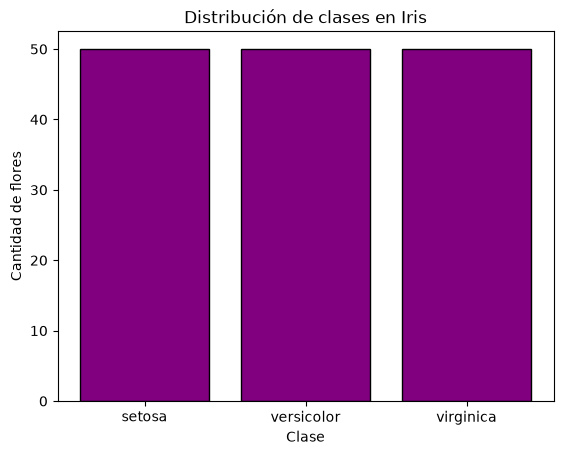

In [7]:
# Ahora muestro los primeros cinco ejemplos, incluida la especie, X.head() lo que hace es tomar
# las primeras cinco flores; la última columna añade la clase correspondiente de y

import matplotlib.pyplot as plt

cantidades = [(y == numero).sum() for numero in range(len(iris.target_names))]

plt.bar(iris.target_names, cantidades, color="purple", edgecolor="black")
plt.title("Distribución de clases en Iris")
plt.xlabel("Clase")
plt.ylabel("Cantidad de flores")
plt.show()

### Interpretación de Iris

El dataset contiene información de 150 flores Iris. Para cada flor se registran cuatro medidas en centímetros: longitud y anchura del sépalo, y longitud y anchura del pétalo.

Las flores pertenecen a tres especies: setosa, versicolor y virginica. Hay 50 ejemplos de cada especie. La tabla presenta cinco flores y el gráfico muestra la cantidad de ejemplos por especie. `X` tiene 150 filas y 4 columnas, y `y` contiene la clase de cada flor.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

### Predicciones iniciales

1. Espero que la regresión logística, el SVM lineal y el MLP sean sensibles a la escala de las características. Los árboles de decisión y los modelos basados en árboles suelen ser menos sensibles.
2. Espero que la regresión logística y el SVM lineal produzcan decisiones más simples, porque son modelos lineales.
3. No puedo asegurar cuál será el mejor modelo antes de probarlos, porque su desempeño depende de los datos, la partición y los hiperparámetros.

In [8]:
# Importo las herrmaientas para los modelos para evaluar las clasificaciones
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

In [9]:
# Primero separamos el conjunto de prueba
X_entrenamiento_validacion, X_prueba, y_entrenamiento_validacion, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Luego separamos la validación del conjunto restante
X_entrenamiento, X_validacion, y_entrenamiento, y_validacion = train_test_split(
    X_entrenamiento_validacion,
    y_entrenamiento_validacion,
    test_size=0.25,
    random_state=42,
    stratify=y_entrenamiento_validacion
)

print("Ejemplos para entrenar:", len(X_entrenamiento))
print("Ejemplos para validar:", len(X_validacion))
print("Ejemplos para probar:", len(X_prueba))

# La división es 60 % para entrenamiento, 20 % para validación y 20 % para prueba. 
# stratify conserva la proporción de cada especie y random_state=42 asegura resultados reproducibles.

Ejemplos para entrenar: 90
Ejemplos para validar: 30
Ejemplos para probar: 30


In [10]:
#Defino las configuraciones que compararemos en validación. 
# Cada lista contiene opciones de hiperparámetros para su modelo 

configuraciones = {
    "Naive Bayes": [
        {"var_smoothing": 1e-9},
        {"var_smoothing": 1e-8}
    ],
    "Regresión logística": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0}
    ],
    "SVM lineal": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0}
    ],
    "Árbol de decisión": [
        {"max_depth": 2},
        {"max_depth": 3}
    ],
    "Random Forest": [
        {"n_estimators": 100, "max_depth": 2},
        {"n_estimators": 100, "max_depth": 4}
    ],
    "Gradient Boosting": [
        {"n_estimators": 50, "learning_rate": 0.05},
        {"n_estimators": 100, "learning_rate": 0.1}
    ],
    "MLP": [
        {"hidden_layer_sizes": (10,), "alpha": 0.0001},
        {"hidden_layer_sizes": (30,), "alpha": 0.001}
    ]
}

print("Modelos configurados:", list(configuraciones.keys()))

# En esta celda solo se encuentran las opciones que probaré 

Modelos configurados: ['Naive Bayes', 'Regresión logística', 'SVM lineal', 'Árbol de decisión', 'Random Forest', 'Gradient Boosting', 'MLP']


In [11]:
# defino cómo construyo cada clasificador.

def crear_modelo(nombre, parametros):
    if nombre == "Naive Bayes":
        clasificador = GaussianNB(**parametros)

    elif nombre == "Regresión logística":
        clasificador = LogisticRegression(
            max_iter=2000,
            **parametros
        )

    elif nombre == "SVM lineal":
        clasificador = SVC(
            kernel="linear",
            **parametros
        )

    elif nombre == "Árbol de decisión":
        clasificador = DecisionTreeClassifier(
            random_state=42,
            **parametros
        )

    elif nombre == "Random Forest":
        clasificador = RandomForestClassifier(
            random_state=42,
            **parametros
        )

    elif nombre == "Gradient Boosting":
        clasificador = GradientBoostingClassifier(
            random_state=42,
            **parametros
        )

    elif nombre == "MLP":
        clasificador = MLPClassifier(
            max_iter=2000,
            random_state=42,
            **parametros
        )

    return make_pipeline(StandardScaler(), clasificador)

    # make_pipeline me ayuda a que primero se estandaricen las características y luego se ajuste el clasificador.

In [12]:
# Entrenó cada configuración con el conjunto de entrenamiento, la compara en validación y selecciona la de mayor F1 macro

mejores_parametros = {}
resultados_validacion = []

for nombre, lista_parametros in configuraciones.items():
    mejor_f1 = -1

    for parametros in lista_parametros:
        modelo = crear_modelo(nombre, parametros)
        modelo.fit(X_entrenamiento, y_entrenamiento)

        predicciones = modelo.predict(X_validacion)
        accuracy = accuracy_score(y_validacion, predicciones)
        f1_macro = f1_score(
            y_validacion,
            predicciones,
            average="macro"
        )

        resultados_validacion.append({
            "Modelo": nombre,
            "Parámetros": str(parametros),
            "Accuracy de validación": accuracy,
            "F1 macro de validación": f1_macro
        })

        if f1_macro > mejor_f1:
            mejor_f1 = f1_macro
            mejores_parametros[nombre] = parametros

tabla_validacion = pd.DataFrame(resultados_validacion)
display(
    tabla_validacion.sort_values(
        "F1 macro de validación",
        ascending=False
    )
)

,Modelo,Parámetros,Accuracy de validación,F1 macro de validación
0,Naive Bayes,{'var_smoothing': 1e-09},0.933333,0.933333
1,Naive Bayes,{'var_smoothing': 1e-08},0.933333,0.933333
3,Regresión logística,{'C': 1.0},0.933333,0.933333
4,Regresión logística,{'C': 10.0},0.933333,0.933333
6,SVM lineal,{'C': 1.0},0.933333,0.933333
5,SVM lineal,{'C': 0.1},0.933333,0.933333
15,MLP,"{'hidden_layer_sizes': (30,), 'alpha': 0.001}",0.933333,0.933333
11,Random Forest,"{'n_estimators': 100, 'max_depth': 4}",0.933333,0.933333
14,MLP,"{'hidden_layer_sizes': (10,), 'alpha': 0.0001}",0.933333,0.933333
12,Gradient Boosting,"{'n_estimators': 50, 'learning_rate': 0.05}",0.933333,0.933333


In [13]:
# Reúno entrenamiento y validación

X_entrenamiento_final = pd.concat(
    [X_entrenamiento, X_validacion]
)

y_entrenamiento_final = pd.concat(
    [y_entrenamiento, y_validacion]
)

print("Ejemplos para el ajuste final:", len(X_entrenamiento_final))

Ejemplos para el ajuste final: 120


In [14]:
# Entreno los modelos con los datos reunidos y creo la tabla

modelos_finales = {}
resultados_prueba = []

for nombre, parametros in mejores_parametros.items():
    modelo = crear_modelo(nombre, parametros)
    modelo.fit(X_entrenamiento_final, y_entrenamiento_final)

    predicciones = modelo.predict(X_prueba)
    modelos_finales[nombre] = modelo

    resultados_prueba.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": str(parametros),
        "Accuracy de prueba": accuracy_score(y_prueba, predicciones),
        "F1 macro de prueba": f1_score(
            y_prueba, predicciones, average="macro"
        )
    })

tabla_prueba = pd.DataFrame(resultados_prueba)
display(tabla_prueba)

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Naive Bayes,StandardScaler,{'var_smoothing': 1e-09},0.966667,0.966583
1,Regresión logística,StandardScaler,{'C': 1.0},0.933333,0.933333
2,SVM lineal,StandardScaler,{'C': 0.1},0.933333,0.933333
3,Árbol de decisión,StandardScaler,{'max_depth': 2},0.933333,0.933333
4,Random Forest,StandardScaler,"{'n_estimators': 100, 'max_depth': 4}",0.933333,0.933333
5,Gradient Boosting,StandardScaler,"{'n_estimators': 50, 'learning_rate': 0.05}",0.966667,0.966583
6,MLP,StandardScaler,"{'hidden_layer_sizes': (10,), 'alpha': 0.0001}",0.966667,0.966583


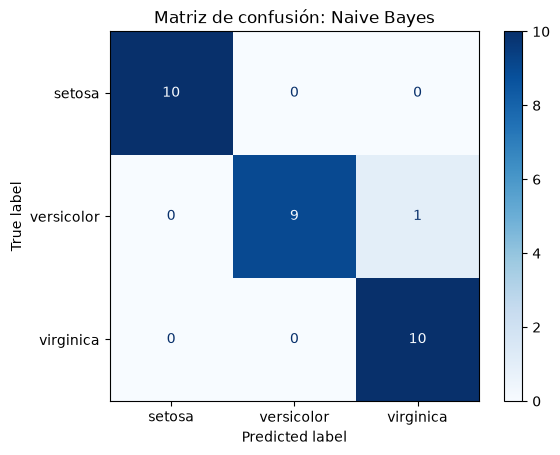

In [34]:
# Matriz de confusión de Naive Bayes:
ConfusionMatrixDisplay.from_estimator(
    modelos_finales["Naive Bayes"],
    X_prueba,
    y_prueba,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Matriz de confusión: Naive Bayes")
plt.show()

La matriz compara las clases reales con las predichas. Las cantidades de la diagonal son las flores que el modelo clasificó correctamente.


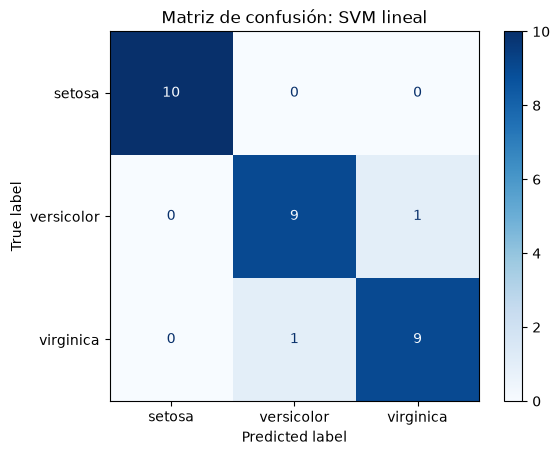

In [16]:
# Matriz de confusión del SVM lineal.

ConfusionMatrixDisplay.from_estimator(
    modelos_finales["SVM lineal"],
    X_prueba,
    y_prueba,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Matriz de confusión: SVM lineal")
plt.show()

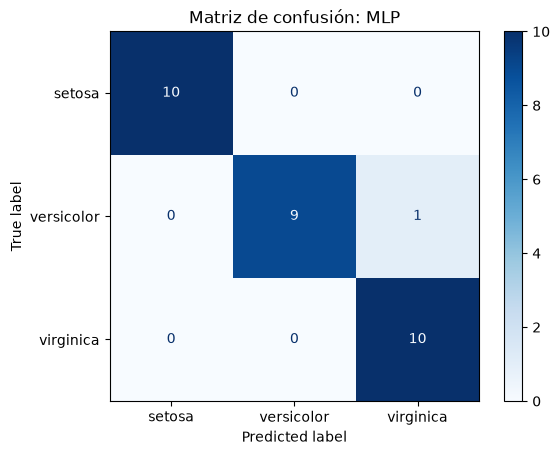

In [36]:
# Matriz de confusión del MLP

ConfusionMatrixDisplay.from_estimator(
    modelos_finales["MLP"],
    X_prueba,
    y_prueba,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Matriz de confusión: MLP")
plt.show()

In [18]:
# Ahora busco errores de dos flores que hayan sido clasificadas incorrectamente por 
# al menos uno de los modelos y muestra sus características, su especie real y las predicciones equivocadas:

errores_encontrados = []

for indice in X_prueba.index:
    predicciones_incorrectas = {}

    for nombre, modelo in modelos_finales.items():
        prediccion = modelo.predict(X_prueba.loc[[indice]])[0]

        if prediccion != y_prueba.loc[indice]:
            predicciones_incorrectas[nombre] = iris.target_names[prediccion]

    if predicciones_incorrectas:
        fila = X_prueba.loc[indice].to_dict()
        fila["Clase real"] = iris.target_names[y_prueba.loc[indice]]
        fila["Predicciones incorrectas"] = predicciones_incorrectas
        errores_encontrados.append(fila)

if errores_encontrados:
    display(pd.DataFrame(errores_encontrados).head(2))
else:
    print("Ningún modelo cometió errores en esta partición de prueba.")

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase real,Predicciones incorrectas
0,6.1,2.6,5.6,1.4,virginica,"{'Regresión logística': 'versicolor', 'SVM lin..."
1,6.7,3.0,5.0,1.7,versicolor,"{'Naive Bayes': 'virginica', 'Regresión logíst..."


### Interpretación de los resultados

1. ¿Cuál fue el modelo con el mejor desempeño?

Naive Bayes, Gradient Boosting y MLP obtuvieron los mejores resultados: accuracy de 0.9667 y F1 macro de 0.9666, aproximadamente 96.7 %. Los otros cuatro modelos alcanzaron 0.9333, aproximadamente 93.3 %.

2. ¿Cuál fue el modelo más sencillo de programar?

Naive Bayes fue el más sencillo de programar, porque tiene una estructura simple.

3. ¿Accuracy y F1 macro cuentan la misma historia?

En esta prueba, accuracy y F1 macro cuentan una historia parecida: muestran el mismo orden general de desempeño para los modelos. Las clases están balanceadas, lo que también ayuda a explicar esa similitud.

4. ¿Cuál es la diferencia entre las métricas macro y micro?

La métrica macro calcula el resultado de cada clase y luego promedia las clases dándoles el mismo peso. La métrica micro reúne los aciertos y errores de todas las clases antes de calcular el resultado. En esta clasificación, micro-F1 coincide con accuracy.

5. ¿Qué aporta el MLP frente a un modelo lineal?

El MLP puede aprender relaciones no lineales mediante sus capas ocultas, mientras que un modelo lineal forma fronteras de decisión lineales. En esta prueba el MLP quedó entre los mejores, aunque su mayor flexibilidad no garantiza siempre un mejor resultado.


### Análisis de dos errores de clasificación

El primer ejemplo corresponde a una flor virginica con sépalo de 6.1 × 2.6 cm y pétalo de 5.6 × 1.4 cm. La regresión logística y el SVM lineal la clasificaron como versicolor.

El segundo ejemplo corresponde a una flor versicolor con sépalo de 6.7 × 3.0 cm y pétalo de 5.0 × 1.7 cm. Naive Bayes la clasificó como virginica.

Estos ejemplos permiten observar que algunas flores presentan características similares a las de otra clase, lo que puede llevar a los modelos a cometer errores de clasificación. Sin embargo, a partir de estos casos aislados no es posible afirmar que una característica específica haya sido la causa del error. Para llegar a una conclusión de ese tipo sería necesario analizar un conjunto más amplio de ejemplos y realizar un estudio adicional sobre la influencia de cada característica en las predicciones de los modelos.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [19]:
# Cargo Dataset Diabetes

from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

In [37]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [38]:
descripcion = diabetes.DESCR.lower()
posicion = descripcion.find("mean centered")

if posicion >= 0:
    print(diabetes.DESCR[posicion - 100 : posicion + 400])
else:
    print("Busca en la descripción las palabras 'scaled' o 'standard deviation'.")

ides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1).

Source URL:
https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html

For more information see:
Bradley Efron, Trevor Hastie, Iain Johnstone and Robert Tibshirani (2004) "Least Angle Regression," Annals of Statistics (with discussion), 407-499.
(https://web.s



### Descripción del dataset Diabetes
El dataset Diabetes contiene información de 442 pacientes. La variable objetivo es numérica y representa una medida de la progresión de la enfermedad un año después de la evaluación inicial de cada paciente.

Las diez variables predictoras incluidas en el conjunto de datos son la edad, el sexo, el índice de masa corporal (BMI), la presión arterial promedio (BP) y seis indicadores obtenidos a partir de análisis de suero sanguíneo (s1-s6). Es importante tener en cuenta que, antes de ser incorporadas al dataset, estas variables fueron centradas y escaladas mediante procedimientos de normalización. Por esta razón, los valores observados no corresponden directamente a edades, medidas corporales ni unidades clínicas en su escala original, sino a versiones transformadas de dichas variables para facilitar el análisis y el entrenamiento de modelos predictivos.

### Predicción inicial

Un modelo más flexible no siempre tendrá menor error en datos nuevos. Puede ajustarse demasiado a los datos de entrenamiento y no generalizar bien. Por eso, compararé los modelos con validación y reservaré la prueba para la evaluación final.

In [22]:
# Importo los modelos y métricas 

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [39]:
# Separar primero el conjunto de prueba
X_reg_entrenamiento_validacion, X_reg_prueba, y_reg_entrenamiento_validacion, y_reg_prueba = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.20,
    random_state=42
)

# Separar validación del conjunto restante
X_reg_entrenamiento, X_reg_validacion, y_reg_entrenamiento, y_reg_validacion = train_test_split(
    X_reg_entrenamiento_validacion,
    y_reg_entrenamiento_validacion,
    test_size=0.25,
    random_state=42
)

print("Ejemplos para entrenar:", len(X_reg_entrenamiento))
print("Ejemplos para validar:", len(X_reg_validacion))
print("Ejemplos para probar:", len(X_reg_prueba))

# Quedan aproximadamente 60 % para entrenamiento, 20 % para validación y 20 % para prueba.

Ejemplos para entrenar: 264
Ejemplos para validar: 89
Ejemplos para probar: 89


In [40]:
# Creo algunas configuraciones para comparar. 
# Las usaremos en validación para decidir qué opción conservar en cada modelo

configuraciones_regresion = {
    "Regresión lineal": [
        {}
    ],
    "Ridge": [
        {"alpha": 0.1},
        {"alpha": 1.0},
        {"alpha": 10.0}
    ],
    "Lasso": [
        {"alpha": 0.01},
        {"alpha": 0.1},
        {"alpha": 1.0}
    ],
    "kNN": [
        {"n_neighbors": 5},
        {"n_neighbors": 15}
    ],
    "Árbol": [
        {"max_depth": 2},
        {"max_depth": 4}
    ],
    "Random Forest": [
        {"n_estimators": 100, "max_depth": 3},
        {"n_estimators": 100, "max_depth": None}
    ],
    "Gradient Boosting": [
        {"n_estimators": 100, "learning_rate": 0.05},
        {"n_estimators": 100, "learning_rate": 0.1}
    ],
    "MLP": [
        {"hidden_layer_sizes": (32,), "alpha": 0.001},
        {"hidden_layer_sizes": (64, 32), "alpha": 0.01}
    ]
}

print("Modelos preparados:", list(configuraciones_regresion.keys()))

Modelos preparados: ['Regresión lineal', 'Ridge', 'Lasso', 'kNN', 'Árbol', 'Random Forest', 'Gradient Boosting', 'MLP']


In [29]:
# Defino definir cómo se crea cada modelo y cuándo se escalan los datos.

def crear_regresor(nombre, parametros):
    if nombre == "Regresión lineal":
        modelo = make_pipeline(
            StandardScaler(),
            LinearRegression(**parametros)
        )

    elif nombre == "Ridge":
        modelo = make_pipeline(
            StandardScaler(),
            Ridge(**parametros)
        )

    elif nombre == "Lasso":
        modelo = make_pipeline(
            StandardScaler(),
            Lasso(max_iter=20000, **parametros)
        )

    elif nombre == "kNN":
        modelo = make_pipeline(
            StandardScaler(),
            KNeighborsRegressor(**parametros)
        )

    elif nombre == "Árbol":
        modelo = DecisionTreeRegressor(
            random_state=42,
            **parametros
        )

    elif nombre == "Random Forest":
        modelo = RandomForestRegressor(
            random_state=42,
            **parametros
        )

    elif nombre == "Gradient Boosting":
        modelo = GradientBoostingRegressor(
            random_state=42,
            **parametros
        )

    elif nombre == "MLP":
        red = make_pipeline(
            StandardScaler(),
            MLPRegressor(
                max_iter=3000,
                random_state=42,
                **parametros
            )
        )
        modelo = TransformedTargetRegressor(
            regressor=red,
            transformer=StandardScaler()
        )

    return modelo                       


In [32]:
# Calculo las tres métricas

import numpy as np

def calcular_metricas(y_real, predicciones):
    return {
        "MAE": mean_absolute_error(y_real, predicciones),
        "RMSE": np.sqrt(mean_squared_error(y_real, predicciones)),
        "R²": r2_score(y_real, predicciones)
    }

# La función recibe los valores reales y las predicciones, y devuelve MAE, RMSE y R². 
# La usaremos primero con validación para comparar las configuraciones.

In [41]:
# Entreno cada configuración y comparo en validación

mejores_parametros_regresion = {}
resultados_validacion_regresion = []

for nombre, lista_parametros in configuraciones_regresion.items():
    menor_rmse = float("inf")

    for parametros in lista_parametros:
        modelo = crear_regresor(nombre, parametros)
        modelo.fit(X_reg_entrenamiento, y_reg_entrenamiento)

        predicciones = modelo.predict(X_reg_validacion)
        metricas = calcular_metricas(
            y_reg_validacion,
            predicciones
        )

        resultados_validacion_regresion.append({
            "Modelo": nombre,
            "Parámetros": str(parametros),
            **metricas
        })

        if metricas["RMSE"] < menor_rmse:
            menor_rmse = metricas["RMSE"]
            mejores_parametros_regresion[nombre] = parametros

tabla_validacion_regresion = pd.DataFrame(
    resultados_validacion_regresion
)

display(
    tabla_validacion_regresion.sort_values("RMSE")
)

,Modelo,Parámetros,MAE,RMSE,R²
6,Lasso,{'alpha': 1.0},42.470345,51.060247,0.524140
5,Lasso,{'alpha': 0.1},42.642441,51.099703,0.523405
2,Ridge,{'alpha': 1.0},42.723050,51.103145,0.523341
3,Ridge,{'alpha': 10.0},42.619698,51.160459,0.522271
1,Ridge,{'alpha': 0.1},42.906384,51.174071,0.522017
4,Lasso,{'alpha': 0.01},42.907269,51.177697,0.521949
0,Regresión lineal,{},42.938900,51.193714,0.521650
8,kNN,{'n_neighbors': 15},44.210487,53.651429,0.474618
11,Random Forest,"{'n_estimators': 100, 'max_depth': 3}",43.388406,53.814665,0.471416
14,Gradient Boosting,"{'n_estimators': 100, 'learning_rate': 0.1}",44.615581,53.906604,0.469608


La tabla ordena las opciones por RMSE de validación. La prueba todavía no se ha usado.

In [47]:
# Reuno los datos de entrenamiento y validación

X_reg_entrenamiento_final = pd.concat([
    X_reg_entrenamiento,
    X_reg_validacion
])

y_reg_entrenamiento_final = pd.concat([
    y_reg_entrenamiento,
    y_reg_validacion
])

print(
    "Ejemplos para el ajuste final:",
    len(X_reg_entrenamiento_final)
)

Ejemplos para el ajuste final: 353


In [48]:
# Ajusto cada configuración final y evaluo los modelos en prueba

modelos_regresion_finales = {}
predicciones_regresion_prueba = {}
resultados_prueba_regresion = []

for nombre, parametros in mejores_parametros_regresion.items():
    modelo = crear_regresor(nombre, parametros)
    modelo.fit(
        X_reg_entrenamiento_final,
        y_reg_entrenamiento_final
    )

    predicciones = modelo.predict(X_reg_prueba)

    modelos_regresion_finales[nombre] = modelo
    predicciones_regresion_prueba[nombre] = predicciones

    metricas = calcular_metricas(
        y_reg_prueba,
        predicciones
    )

    resultados_prueba_regresion.append({
        "Modelo": nombre,
        **metricas
    })

tabla_prueba_regresion = pd.DataFrame(
    resultados_prueba_regresion
).sort_values("RMSE")

display(tabla_prueba_regresion)

,Modelo,MAE,RMSE,R²
7,MLP,39.693210,51.917598,0.491250
5,Random Forest,42.844500,52.730177,0.475200
2,Lasso,42.802984,53.146666,0.466877
6,Gradient Boosting,44.529637,53.732952,0.455050
1,Ridge,42.811999,53.777454,0.454147
0,Regresión lineal,42.794095,53.853446,0.452603
3,kNN,45.319850,55.260957,0.423615
4,Árbol,49.365345,61.118734,0.294943


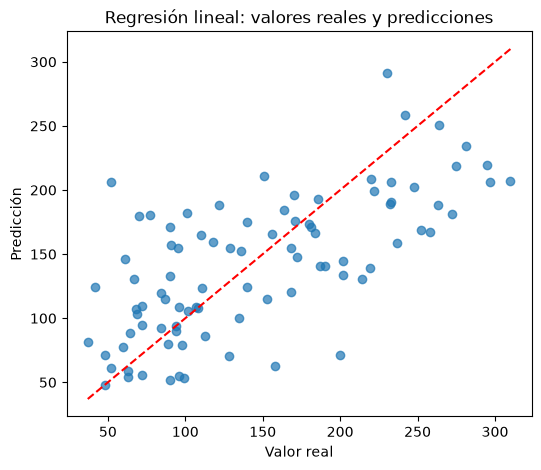

In [51]:
# Gráfico de valores reales frente a predicciones de la regresión lineal

pred_lineal = predicciones_regresion_prueba["Regresión lineal"]

plt.figure(figsize=(6, 5))
plt.scatter(y_reg_prueba, pred_lineal, alpha=0.7)

minimo = min(y_reg_prueba.min(), pred_lineal.min())
maximo = max(y_reg_prueba.max(), pred_lineal.max())
plt.plot([minimo, maximo], [minimo, maximo], "r--")

plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title("Regresión lineal: valores reales y predicciones")
plt.show()

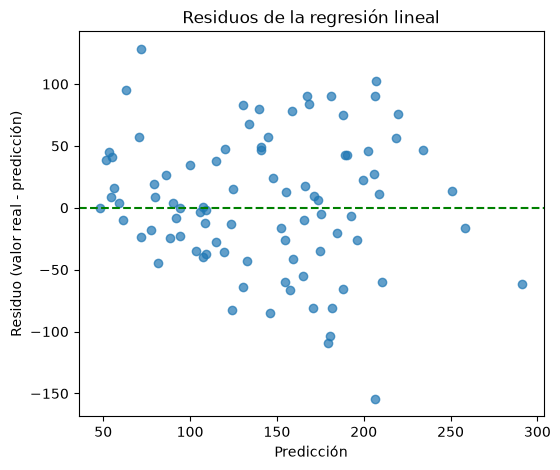

In [56]:
# Grafico los residuos de la regresión lineal:

residuos_lineal = y_reg_prueba.to_numpy() - pred_lineal

plt.figure(figsize=(6, 5))
plt.scatter(pred_lineal, residuos_lineal, alpha=0.7)
plt.axhline(0, color="green", linestyle="--")

plt.xlabel("Predicción")
plt.ylabel("Residuo (valor real - predicción)")
plt.title("Residuos de la regresión lineal")
plt.show()

En el gráfico, los residuos aparecen tanto por encima como por debajo de cero, sin un patrón claro de sobrestimación o subestimación general. Sin embargo, algunos puntos están bastante alejados de cero, lo que indica errores grandes en ciertos casos. El gráfico muestra dónde se equivoca el modelo.

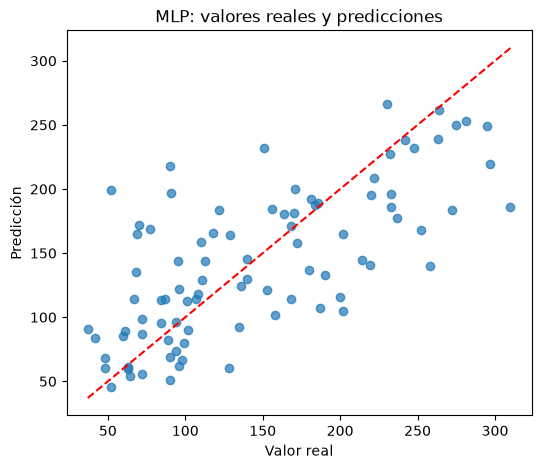

In [58]:
# Comparo los valores reales con las predicciones del MLP

pred_mlp = predicciones_regresion_prueba["MLP"]

plt.figure(figsize=(6, 5))
plt.scatter(y_reg_prueba, pred_mlp, alpha=0.7)

minimo = min(y_reg_prueba.min(), pred_mlp.min())
maximo = max(y_reg_prueba.max(), pred_mlp.max())
plt.plot([minimo, maximo], [minimo, maximo], "r--")

plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title("MLP: valores reales y predicciones")
plt.show()

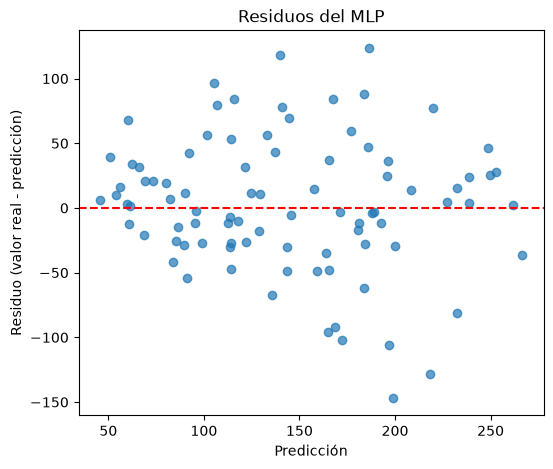

In [59]:
# Residuos del MPL

residuos_mlp = y_reg_prueba.to_numpy() - pred_mlp

plt.figure(figsize=(6, 5))
plt.scatter(pred_mlp, residuos_mlp, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicción")
plt.ylabel("Residuo (valor real - predicción)")
plt.title("Residuos del MLP")
plt.show()

In [60]:
# Encontrar los dos errores absolutos más grandes de la regresión lineal

errores_abs_lineal = np.abs(residuos_lineal)
indices_mayores_lineal = np.argsort(errores_abs_lineal)[-2:][::-1]

ejemplos_lineal = X_reg_prueba.iloc[indices_mayores_lineal].copy()
ejemplos_lineal["Valor real"] = y_reg_prueba.iloc[indices_mayores_lineal].values
ejemplos_lineal["Predicción"] = pred_lineal[indices_mayores_lineal]
ejemplos_lineal["Error absoluto"] = errores_abs_lineal[indices_mayores_lineal]

display(ejemplos_lineal)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.03184,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,206.493375,154.493375
77,-0.096328,-0.044642,-0.036385,-0.074527,-0.03872,-0.027618,0.015505,-0.039493,-0.074093,-0.001078,200.0,71.666726,128.333274


In [62]:
# Encontrar los dos errores absolutos más grandes del MLP

errores_abs_mlp = np.abs(residuos_mlp)
indices_mayores_mlp = np.argsort(errores_abs_mlp)[-2:][::-1]

ejemplos_mlp = X_reg_prueba.iloc[indices_mayores_mlp].copy()
ejemplos_mlp["Valor real"] = y_reg_prueba.iloc[indices_mayores_mlp].values
ejemplos_mlp["Predicción"] = pred_mlp[indices_mayores_mlp]
ejemplos_mlp["Error absoluto"] = errores_abs_mlp[indices_mayores_mlp]

display(ejemplos_mlp)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Valor real,Predicción,Error absoluto
56,-0.041840,-0.044642,0.041218,-0.026328,-0.031840,-0.030437,-0.036038,0.002943,0.033654,-0.017646,52.0,198.861978,146.861978
199,0.041708,-0.044642,-0.045007,0.034508,0.043837,-0.015719,0.037595,-0.014401,0.089897,0.007207,90.0,218.198871,128.198871


In [65]:
# Defino varios valores de alpha, que controla la intensidad de la penalización

alphas_regularizacion = [0.01, 0.1, 1, 10, 100]

# Probaremos estos valores en Ridge y Lasso



In [68]:
# Mido el RMSE en entrenamiento y validación, la magnitud de los coeficientes y cuántos coeficientes de Lasso son cero

resultados_regularizacion = []
coeficientes_regularizacion = {}

for nombre in ["Ridge", "Lasso"]:
    for alpha in alphas_regularizacion:
        modelo = crear_regresor(nombre, {"alpha": alpha})
        modelo.fit(X_reg_entrenamiento, y_reg_entrenamiento)

        pred_entrenamiento = modelo.predict(X_reg_entrenamiento)
        pred_validacion = modelo.predict(X_reg_validacion)

        rmse_entrenamiento = calcular_metricas(
            y_reg_entrenamiento,
            pred_entrenamiento
        )["RMSE"]

        rmse_validacion = calcular_metricas(
            y_reg_validacion,
            pred_validacion
        )["RMSE"]

        estimador = modelo.named_steps[nombre.lower()]
        coeficientes = estimador.coef_
        coeficientes_regularizacion[(nombre, alpha)] = coeficientes

        resultados_regularizacion.append({
            "Modelo": nombre,
            "Alpha": alpha,
            "RMSE entrenamiento": rmse_entrenamiento,
            "RMSE validación": rmse_validacion,
            "Magnitud de coeficientes": np.linalg.norm(coeficientes),
            "Coeficientes en cero": int(np.isclose(coeficientes, 0).sum())
                if nombre == "Lasso" else "—"
        })

tabla_regularizacion = pd.DataFrame(resultados_regularizacion)
display(tabla_regularizacion)

,Modelo,Alpha,RMSE entrenamiento,RMSE validación,Magnitud de coeficientes,Coeficientes en cero
0,Ridge,0.01,54.610371,51.191558,77.851480,—
1,Ridge,0.10,54.611033,51.174071,75.549068,—
2,Ridge,1.00,54.643849,51.103145,60.880338,—
3,Ridge,10.00,54.842556,51.160459,41.916915,—
4,Ridge,100.00,55.859422,51.736930,32.778169,—
5,Lasso,0.01,54.610805,51.177697,76.051760,0
6,Lasso,0.10,54.654421,51.099703,58.770809,0
7,Lasso,1.00,54.912377,51.060247,41.985541,1
8,Lasso,10.00,58.425064,53.151103,31.128626,6
9,Lasso,100.00,78.846190,75.639205,0.000000,10


In [75]:
# Observo el valor de cada coeficiente de Ridge y Lasso con cada alpha

filas_coeficientes = []

for (nombre, alpha), coeficientes in coeficientes_regularizacion.items():
    fila = {
        "Modelo": nombre,
        "Alpha": alpha
    }

    for caracteristica, coeficiente in zip(
        X_diabetes.columns,
        coeficientes
    ):
        fila[caracteristica] = coeficiente

    filas_coeficientes.append(fila)

tabla_coeficientes = pd.DataFrame(filas_coeficientes)
display(tabla_coeficientes)

,Modelo,Alpha,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,Ridge,0.01,1.134042,-11.359527,25.080240,15.166184,-50.873864,27.299236,10.746375,15.004856,37.187169,3.818674
1,Ridge,0.10,1.152980,-11.361162,25.110988,15.156098,-48.920843,25.740995,9.939733,14.769776,36.462432,3.832237
2,Ridge,1.00,1.282151,-11.356686,25.295650,15.075356,-35.689267,15.229031,4.451488,13.125472,31.550568,3.934695
3,Ridge,10.00,1.555538,-10.982528,25.059470,14.635693,-11.733845,-2.935095,-5.807967,9.315655,22.493429,4.364107
4,Ridge,100.00,2.132563,-7.845466,20.158068,12.049352,-3.134526,-5.110389,-8.651536,6.540164,16.439189,5.741388
5,Lasso,0.01,1.136354,-11.348493,25.102718,15.153730,-49.346526,26.121962,10.067391,14.738517,36.652569,3.819039
6,Lasso,0.10,1.176828,-11.251054,25.337227,15.031334,-33.574861,13.909548,3.120231,12.098388,31.089381,3.836335
7,Lasso,1.00,0.333810,-9.539173,25.664674,14.196296,-11.507532,-0.000000,-6.936049,4.627055,24.460680,3.346866
8,Lasso,10.00,0.000000,-0.000000,23.649283,6.533835,-0.000000,-0.000000,-3.785807,0.000000,18.779762,0.000000
9,Lasso,100.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


### Interpretación de los resultados

**1. ¿Qué modelo tuvo el mejor desempeño?**

El MLP tuvo el mejor desempeño en la prueba: obtuvo el MAE más bajo (39.69), el RMSE más bajo (51.92) y el R² más alto (0.491). Fue el mejor entre los modelos comparados en esta partición.

**2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?**

MAE calcula el promedio de los errores absolutos, mientras que RMSE da más importancia a los errores grandes al elevarlos al cuadrado. Por esta razón, cuando existen algunas predicciones muy alejadas de los valores reales, el RMSE suele ser más alto.

**3. ¿Cómo se interpreta un R² negativo?**

Un R² negativo significa que el modelo rindió peor que una predicción constante igual al promedio de los valores reales. En esta prueba, los R² fueron positivos; el del MLP fue 0.491.

**4. ¿Qué efecto tuvo aumentar la regularización?**

Al aumentar `alpha`, los coeficientes se hicieron más pequeños. En Ridge ninguno llegó a cero: la magnitud total bajó de 77.85 con alpha 0.01 a 32.78 con alpha 100. En Lasso, alpha 1 dejó un coeficiente en cero, alpha 10 dejó seis y alpha 100 dejó los diez en cero. El menor RMSE de validación fue aproximadamente 51.10 para Ridge con alpha 1 y 51.06 para Lasso con alpha 1. Con una penalización muy alta, el error de validación aumentó, especialmente en Lasso.

**5. ¿Qué puede explicar los errores grandes?**

En la regresión lineal, un caso tenía un valor real de 52 y una predicción de 206.49; otro tenía un valor real de 200 y una predicción de 71.67. En el MLP, el primer caso tenía un valor real de 52 y una predicción de 198.86; otro tenía un valor real de 90 y una predicción de 218.20. Estos casos muestran que los modelos pueden equivocarse bastante para algunos pacientes. Las características están centradas y escaladas, por lo que sus valores no corresponden directamente a las unidades clínicas originales. Con estos ejemplos no se puede determinar la causa exacta de los errores.

**6. ¿Un coeficiente predictivo demuestra una relación causal?**

No. Un coeficiente puede ayudar a predecir, pero no demuestra que una variable cause un cambio en la progresión de la enfermedad. Puede haber otras variables o explicaciones relacionadas que el modelo no contempla.